<a href="https://colab.research.google.com/github/Shreevatsa-NP/BIS/blob/main/trafficsignal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OPTIMAL TRAFFIC SIGNAL TIMING
North : 5.27 seconds
South : 55.92 seconds
East : 6.71 seconds
West : 52.1 seconds
Minimum waiting cost: 8273.71


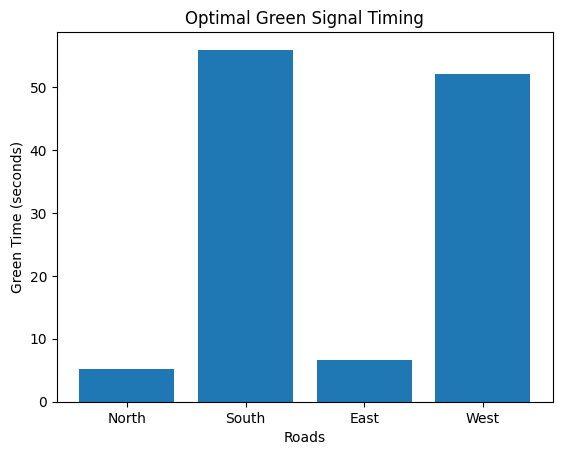

In [19]:

import numpy as np
import random
import matplotlib.pyplot as plt

queue = np.array([20, 35, 15, 30])


TOTAL_TIME = 120
MIN_TIME = 10
MAX_TIME = 50

POP_SIZE = 30
GENERATIONS = 50

population = [
    np.random.dirichlet(np.ones(4)) * TOTAL_TIME
    for _ in range(POP_SIZE)
]

best_history = []

def fitness(time):
    waiting = np.sum(queue * (TOTAL_TIME - time))
    return waiting
for gen in range(GENERATIONS):

    population.sort(key=fitness)

    new_population = population[:2]

    while len(new_population) < POP_SIZE:

        p1, p2 = random.sample(population[:15], 2)


        child = (p1 + p2) / 2

        if random.random() < 0.3:
            child += np.random.normal(0, 5, 4)

        child = np.clip(child, MIN_TIME, MAX_TIME)

        child = child / np.sum(child) * TOTAL_TIME

        new_population.append(child)

    population = new_population

    best = min(population, key=fitness)
    best_history.append(fitness(best))


best = min(population, key=fitness)

print("OPTIMAL TRAFFIC SIGNAL TIMING")

roads = ["North", "South", "East", "West"]

for i in range(4):
    print(roads[i], ":", round(best[i], 2), "seconds")

print("Minimum waiting cost:", round(fitness(best), 2))
plt.bar(roads, best)
plt.xlabel("Roads")
plt.ylabel("Green Time (seconds)")
plt.title("Optimal Green Signal Timing")
plt.show()
